# Part 3. Additional models, comparison and error analysis

Project 5, Loan Approval, target `Credit Default`. Part 1 (Denis Shin's EDA) audited the data and found two anomalous values: Credit Score > 850 and Current Loan Amount = 99999999. Part 2 (Abylay Latiyev) put the preprocessing into `credit_pipeline.py`, fixed a 5,400 / 1,350 split and trained a logistic regression. Its validation result for class 1: Precision 0.458, Recall 0.647, F1 0.536. Without the anomaly flags F1 drops to 0.472.

This notebook trains two tree ensembles, tunes the decision threshold, compares everything with the logistic regression, analyses the errors and evaluates the chosen model on test once.

**Models.**

- *Random Forest* averages hundreds of trees, each grown on a bootstrap sample with a random subset of features at every split. Averaging reduces the variance of a single tree. `class_weight="balanced_subsample"` recomputes class weights inside every bootstrap sample, since class 1 is only 28.5 % of the data.
- *HistGradientBoosting* builds trees one after another, each fitting the errors of the sum of the previous ones (gradient descent on the log-loss). Features are binned into 255 intervals, which makes training fast, and missing values are handled natively. It is scikit-learn's implementation of the LightGBM approach, so no new dependency is needed.
- *Logistic regression* from part 2 stays as the reference point.

**Threshold.** By default class 1 is predicted when the probability is ≥ 0.5. With imbalanced classes that is rarely the best cut-off for F1. `TunedThresholdClassifierCV` tries 100 thresholds on 5 folds of the training part and keeps the one with the highest mean F1. Validation and test are not used. Studies on credit scoring report that threshold tuning often helps more than resampling such as SMOTE ([arXiv 1907.12996](https://export.arxiv.org/pdf/1907.12996)), and that tree ensembles usually, but not always, beat logistic regression ([MDPI Systems 13/7/581](https://www.mdpi.com/2079-8954/13/7/581), [SciTePress 2025](https://www.scitepress.org/publishedPapers/2025/137012/pdf/index.html)). Docs: [TunedThresholdClassifierCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html).

**Rules.** The split comes only from `cp.load_split()`. All parameters and thresholds are fitted on the training part. Validation is used only to compare and choose models. Test labels are loaded once, in section 6.

In [1]:
import json
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate

import credit_pipeline as cp
import participant3 as p3

warnings.filterwarnings('ignore', category=UserWarning)
OUT = Path('artifacts/participant3')
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

X_full, y_full, X_test = cp.load_data()
idx_tr, idx_va = cp.load_split()
X_tr, y_tr = X_full.loc[idx_tr], y_full.loc[idx_tr]
X_va, y_va = X_full.loc[idx_va], y_full.loc[idx_va]
print(f'train {len(X_tr)}, validation {len(X_va)}, test {len(X_test)}; class 1 share in train {y_tr.mean():.3f}')

train 5400, validation 1350, test 750; class 1 share in train 0.285


## 1. Cross-validation on the training part

Each model runs in two variants: with the anomaly flags (`score_scale_flag`, `loan_sentinel_flag`) and without them. First a 5-fold CV at threshold 0.5, then threshold tuning on the same folds. ROC AUC does not depend on the threshold and shows how well the model ranks applicants.

In [2]:
cv = StratifiedKFold(5, shuffle=True, random_state=cp.RANDOM_STATE)
rows, tuned = [], {}
for flags in (True, False):
    for name, pipe in p3.make_models(flags).items():
        res = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring=['precision', 'recall', 'f1', 'roc_auc'])
        t = p3.tune_threshold(pipe, X_tr, y_tr)
        tuned[(name, flags)] = t
        rows.append({'model': name, 'flags': flags,
                     **{m: res[f'test_{m}'].mean() for m in ['precision', 'recall', 'f1', 'roc_auc']},
                     'f1_sd': res['test_f1'].std(),
                     'tuned_threshold': t.best_threshold_, 'tuned_cv_f1': t.best_score_})
cv_table = pd.DataFrame(rows)
cv_table.to_csv(OUT / 'cv_comparison.csv', index=False)
cv_table.round(3)

,model,flags,precision,recall,f1,roc_auc,f1_sd,tuned_threshold,tuned_cv_f1
0,logreg,True,0.479,0.658,0.554,0.778,0.012,0.505,0.556
1,random_forest,True,0.579,0.492,0.532,0.774,0.018,0.421,0.553
2,hist_gb,True,0.518,0.514,0.516,0.757,0.016,0.354,0.538
3,logreg,False,0.406,0.605,0.486,0.676,0.011,0.434,0.494
4,random_forest,False,0.477,0.412,0.442,0.704,0.019,0.359,0.512
5,hist_gb,False,0.428,0.484,0.454,0.688,0.012,0.287,0.508


Columns `precision` to `f1_sd` use threshold 0.5. `tuned_cv_f1` uses the tuned threshold on the same five folds; the threshold was picked on these folds, so this number is slightly optimistic. The fair comparison is validation in the next section.

At threshold 0.5 the logistic regression has the best CV F1 (0.554) and ROC AUC (0.778). The forests are more precise but miss more defaults; after tuning, Random Forest catches up (0.553). Removing the flags costs every model 0.04–0.07 F1.

## 2. Validation comparison

Each model with its tuned threshold was fitted on the 5,400 training rows and now predicts the 1,350 validation rows once. The part 2 rows are copied from its metrics file.

In [3]:
val_rows, proba = [], {}
for (name, flags), t in tuned.items():
    p = t.predict_proba(X_va)[:, 1]
    proba[(name, flags)] = p
    val_rows.append({'model': name, 'flags': flags, 'threshold': t.best_threshold_,
                     **p3.class1_metrics(y_va, (p >= t.best_threshold_).astype(int)),
                     'roc_auc': roc_auc_score(y_va, p)})
p2 = pd.read_csv('artifacts/participant2/baseline_validation_metrics.csv')
p2 = p2.set_index('model').loc[['Logistic regression (baseline)', 'without anomaly flags']]
for (_, r), flags in zip(p2.iterrows(), (True, False)):
    val_rows.append({'model': 'logreg (part 2, threshold 0.5)', 'flags': flags, 'threshold': 0.5,
                     'precision': r.Precision, 'recall': r.Recall, 'f1': r.F1, 'roc_auc': np.nan})
val_table = pd.DataFrame(val_rows).sort_values(['flags', 'f1'], ascending=False)
val_table.to_csv(OUT / 'validation_comparison.csv', index=False)
val_table.round(3)

,model,flags,threshold,precision,recall,f1,roc_auc
6,"logreg (part 2, threshold 0.5)",True,0.500,0.458,0.647,0.536,NaN
0,logreg,True,0.505,0.461,0.639,0.535,0.747
1,random_forest,True,0.421,0.452,0.616,0.521,0.732
2,hist_gb,True,0.354,0.412,0.691,0.517,0.732
5,hist_gb,False,0.287,0.358,0.826,0.499,0.664
4,random_forest,False,0.359,0.365,0.748,0.491,0.671
3,logreg,False,0.434,0.355,0.735,0.478,0.649
7,"logreg (part 2, threshold 0.5)",False,0.500,0.390,0.597,0.472,NaN


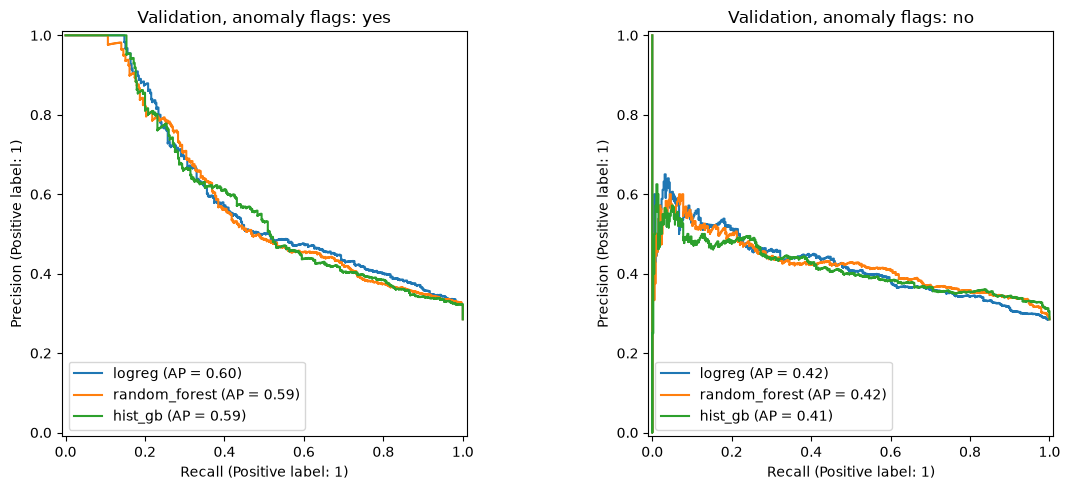

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, flags in zip(axes, (True, False)):
    for name in ['logreg', 'random_forest', 'hist_gb']:
        PrecisionRecallDisplay.from_predictions(y_va, proba[(name, flags)], name=name, ax=ax)
    ax.set_title(f'Validation, anomaly flags: {"yes" if flags else "no"}')
fig.tight_layout(); fig.savefig(FIG / 'pr_curves.png', dpi=120); plt.show()

With the flags, neither tree model beats the baseline: Random Forest reaches F1 0.521 and HistGradientBoosting 0.517, against 0.535–0.536 for logistic regression. Without the flags the order flips: HistGradientBoosting 0.499 and Random Forest 0.491 are ahead of logistic regression (0.478 tuned, 0.472 in part 2). Their tuned thresholds are low (0.29–0.36), so they buy recall (0.75–0.83) with precision.

## 3. Feature contribution

`permutation_importance` shuffles one raw validation column and measures the drop in F1, without refitting. The anomaly flags are derived from `Credit Score` and `Current Loan Amount`, so their effect shows up in the importance of those two columns.

In [5]:
best_tree = val_table[val_table.model.isin(['random_forest', 'hist_gb']) & val_table['flags']].iloc[0].model
imp_rows = []
for flags in (True, False):
    r = permutation_importance(tuned[(best_tree, flags)], X_va, y_va, scoring='f1',
                               n_repeats=10, random_state=cp.RANDOM_STATE, n_jobs=-1)
    imp_rows.append(pd.Series(r.importances_mean, index=X_va.columns, name=f'flags={flags}'))
importance = pd.concat(imp_rows, axis=1).sort_values('flags=True', ascending=False)
importance.to_csv(OUT / 'permutation_importance.csv')
print('model:', best_tree)
importance.round(3).head(10)

model: random_forest


,flags=True,flags=False
Credit Score,0.073,0.005
Current Loan Amount,0.040,0.041
Annual Income,0.037,0.023
Term,0.031,0.011
Maximum Open Credit,0.015,0.001
Home Ownership,0.012,-0.003
Years in current job,0.010,0.006
Purpose,0.010,-0.001
Months since last delinquent,0.009,-0.001
Monthly Debt,0.004,0.007


With the flags, `Credit Score` is the most important column (F1 drop 0.073). Without them its importance falls to 0.005: almost all of its value comes from the "score above 850" marker, not from the score itself. `Current Loan Amount` keeps the same importance (0.040 vs 0.041), so the forest also learns the 99999999 value from the raw amount.

## 4. Model choice

The rule is fixed before test is touched: take the highest validation F1 among the tuned models. If a simpler model is within 0.01, take the simpler one (logreg, then random_forest, then hist_gb). On a tie the variant with flags wins, because parts 1 and 2 kept them as domain cleaning.

In [6]:
order = {'logreg': 0, 'random_forest': 1, 'hist_gb': 2}
cand = val_table[val_table.model.isin(order)].copy()
best_f1 = cand.f1.max()
close = cand[cand.f1 >= best_f1 - 0.01].assign(rank=lambda d: d.model.map(order) - d['flags'].astype(int) * 0.1)
chosen = close.sort_values('rank').iloc[0]
CHOSEN = (chosen.model, bool(chosen['flags']))
print('chosen:', CHOSEN, f'validation F1 {chosen.f1:.3f}')

chosen: ('logreg', True) validation F1 0.535


## 5. Error analysis

Errors of the chosen model on validation. FN is a missed class 1, FP a false alarm. Error shares are computed per group and compared with the part 2 logistic regression on the same rows.


Term (share of rows by error type):
kind           FN     FP     ok
Term                           
Long Term   0.019  0.457  0.524
Short Term  0.133  0.125  0.742

score_missing (share of rows by error type):
kind              FN     FP     ok
score_missing                     
False          0.103  0.177  0.720
True           0.101  0.350  0.549

score_scale_flag (share of rows by error type):
kind                 FN     FP     ok
score_scale_flag                     
0                 0.108  0.223  0.669
1                 0.000  0.000  1.000

loan_sentinel_flag (share of rows by error type):
kind                   FN    FP     ok
loan_sentinel_flag                    
0                   0.116  0.24  0.644
1                   0.000  0.00  1.000

Home Ownership (share of rows by error type):
kind               FN     FP     ok
Home Ownership                     
Have Mortgage   0.000  0.000  1.000
Home Mortgage   0.121  0.192  0.687
Own Home        0.132  0.132  0.737
Rent          

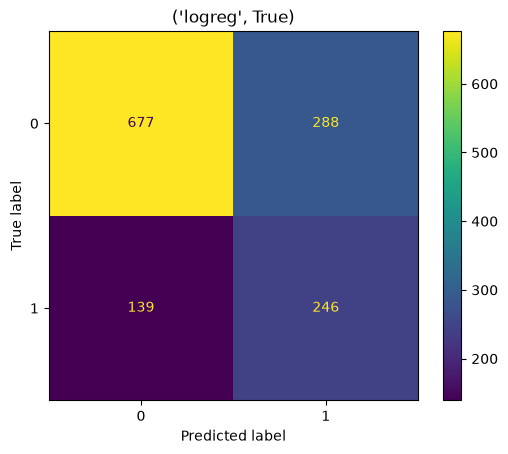

In [7]:
t = tuned[CHOSEN]
p = proba[CHOSEN]
pred = (p >= t.best_threshold_).astype(int)
clean = cp.DomainCleaner().fit(X_tr).transform(X_va)
err = pd.DataFrame({'row': X_va.index, 'y_true': y_va.values, 'proba': p, 'y_pred': pred,
                    'model': f'{CHOSEN[0]}, flags={CHOSEN[1]}'})
err.to_csv(OUT / 'validation_predictions.csv', index=False)
err['kind'] = np.select([(err.y_true == 1) & (err.y_pred == 0), (err.y_true == 0) & (err.y_pred == 1)],
                        ['FN', 'FP'], 'ok')
seg = pd.DataFrame({'Term': X_va.Term.values,
                    'score_missing': X_va['Credit Score'].isna().values,
                    'score_scale_flag': clean.score_scale_flag.values,
                    'loan_sentinel_flag': clean.loan_sentinel_flag.values,
                    'Home Ownership': X_va['Home Ownership'].values})
for col in seg:
    g = pd.concat([seg[col], err.kind], axis=1).groupby(col).kind.value_counts(normalize=True).unstack(fill_value=0)
    print(f'\n{col} (share of rows by error type):'); print(g.round(3))
ConfusionMatrixDisplay.from_predictions(y_va, pred); plt.title(f'{CHOSEN}'); plt.savefig(FIG / 'confusion_chosen.png', dpi=120); plt.show()

In [8]:
base = pd.read_csv('artifacts/participant2/baseline_validation_predictions.csv').set_index('row').loc[err.row]
b_ok = base.y_pred.values == base.y_true.values
c_ok = err.y_pred.values == err.y_true.values
print('fixed vs baseline:', int((~b_ok & c_ok).sum()))
print('broken vs baseline:', int((b_ok & ~c_ok).sum()))
print('wrong in both:', int((~b_ok & ~c_ok).sum()))
print('\nmissed class 1 (FN) vs found class 1 (TP), feature medians:')
fn = err.kind.values == 'FN'; tp = (err.y_true.values == 1) & (err.y_pred.values == 1)
num = ['Credit Score', 'Annual Income', 'Current Loan Amount', 'Monthly Debt', 'Years of Credit History']
pd.DataFrame({'FN': clean.loc[fn, num].median(), 'TP': clean.loc[tp, num].median()}).round(1)

fixed vs baseline: 7


broken vs baseline: 3
wrong in both: 424

missed class 1 (FN) vs found class 1 (TP), feature medians:


,FN,TP
Credit Score,732.5,710.0
Annual Income,1056077.0,988009.5
Current Loan Amount,220066.0,330033.0
Monthly Debt,15840.0,16500.5
Years of Credit History,17.1,16.8


What the errors show:

- Rows with either flag are always classified correctly. All remaining errors come from ordinary rows.
- Long-term loans are the main source of false alarms: 45.7 % of them are FP, against 12.5 % for short-term loans. The model treats `Term = Long Term` as a strong risk sign and flags almost every such applicant.
- Rows with a missing Credit Score (and income) get FP twice as often as the rest (35.0 % vs 17.7 %): median imputation alone does not recover what is lost.
- Missed defaults look like good applicants: higher median score (732.5 vs 710) and income, smaller loans. Nothing in the 16 features separates them.
- The tuned model differs from the part 2 baseline on only 10 of 1,350 rows (7 fixed, 3 broken). 424 rows are wrong for both, so these errors come from the features, not from the model settings.

## 6. Final test evaluation

The chosen model is refitted on all 6,750 train rows (training part + validation), and its threshold is tuned again on 5 folds of those rows. Then test labels are loaded once. All 750 test rows stay in place.

In [9]:
pipe = p3.make_models(CHOSEN[1])[CHOSEN[0]]
final = p3.tune_threshold(pipe, X_full, y_full)
test_pred = final.predict(X_test)
assert len(test_pred) == len(X_test) == 750
y_test = cp.load_test_labels()  # the only call
test_metrics = {'model': CHOSEN[0], 'anomaly_flags': CHOSEN[1], 'threshold': float(final.best_threshold_),
                **p3.class1_metrics(y_test, test_pred),
                'roc_auc': float(roc_auc_score(y_test, final.predict_proba(X_test)[:, 1]))}
(OUT / 'test_metrics.json').write_text(json.dumps(test_metrics, indent=2))
test_metrics

{'model': 'logreg',
 'anomaly_flags': True,
 'threshold': 0.505158127128665,
 'precision': 0.39932885906040266,
 'recall': 0.6329787234042553,
 'f1': 0.4897119341563786,
 'roc_auc': 0.7559438176724464}

## 7. Conclusion

| Model (class 1) | Precision | Recall | F1 |
|---|---|---|---|
| Logistic regression, part 2, validation | 0.458 | 0.647 | 0.536 |
| Logistic regression, tuned threshold, validation | 0.461 | 0.639 | 0.535 |
| Random Forest, tuned threshold, validation | 0.452 | 0.616 | 0.521 |
| HistGradientBoosting, tuned threshold, validation | 0.412 | 0.691 | 0.517 |
| **Logistic regression, final, test** | **0.399** | **0.633** | **0.490** |

1. The tree ensembles did not beat logistic regression on this data. With the anomaly flags it stays first in CV and on validation, so it is the final model. The trees win only without the flags (F1 0.499 vs 0.478), when the remaining signal is non-linear and weak.
2. Threshold tuning on training folds moved the logistic regression threshold only to 0.505; for this model `class_weight="balanced"` already does the job. For the trees it mattered: thresholds of 0.29–0.42 raised recall by 0.1–0.3.
3. On test F1 is 0.490, lower than 0.535 on validation, while ROC AUC stays close (0.756 vs 0.747). Ranking quality held; precision dropped. Validation was not fully blind, because the EDA looked at the whole training target and the preprocessing rules came from it. Test is the honest estimate.
4. The two anomaly flags give most of the gain: removing them costs 0.04–0.07 F1 in every model, and every flagged row is predicted correctly. The data does not tell whether this is a real signal (a scoring system that writes risky clients on a different scale) or an artefact of how the dataset was assembled. If the second is true, the realistic quality is the no-flags row, about F1 0.47–0.50.
5. Most errors are false alarms on long-term loans and on applicants with no credit score. More data on these groups would help more than another model.

Artifacts: `artifacts/participant3/` (`cv_comparison.csv`, `validation_comparison.csv`, `permutation_importance.csv`, `validation_predictions.csv`, `test_metrics.json`, `figures/`).